# ICNF Fire Perimeters

We want to import and investigate the fire perimeters found online to identify a suitable study area.

(2765, 23)
EPSG:4326


<Axes: xlabel='Geodetic longitude [degree]', ylabel='Geodetic latitude [degree]'>

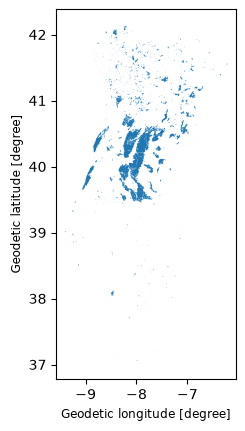

In [53]:
import requests
import zipfile
from pathlib import Path
import geopandas as gpd
from shapely.geometry import box

# Load it
fp = gpd.read_file("../Data/burn_areas_2017/ardida_2017.shp") # Path to fire primeter data
fp = fp.to_crs("EPSG:4326")

print(fp.shape)
print(fp.crs)
fp.head()
fp.plot()

This shows us all the fire perimeters in Portugal from 2017. There are nearly 3,000 perimeters over the whole of Portugal. This is far more than we require, so lets clip a smaller subset of the geometries. 

In [54]:
# Portugal Area of Interest
aoi_bb = [-8.38, 39.78, -7.72, 40.15]

# Create bounding box in EPSG:4326
bbox = box(*aoi_bb)

<Axes: xlabel='Geodetic longitude [degree]', ylabel='Geodetic latitude [degree]'>

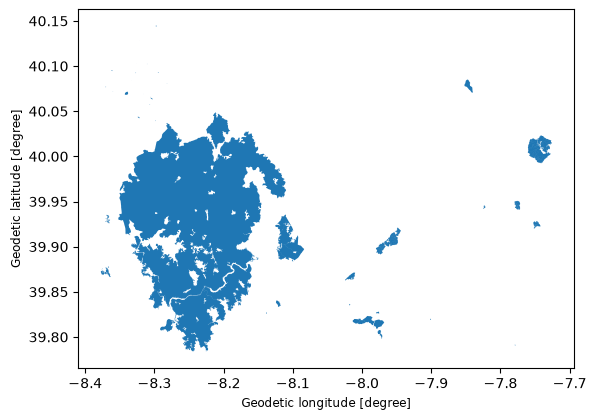

In [55]:
# Clip the perimeters to only include those contained in the area of interest
fp_clip = fp[fp.within(bbox)] 
fp_clip.plot()

Visually, we can see that this matches with the area we have decided to study.

In [56]:
fp_clip

,Cod_SGIF,Cod_ANEPC,Ano,DH_Inicio,DH_1Interv,DH_Fim,Duracao_m,PI_DICOFRE,PI_NUTS3,PI_Distrit,...,Causa_Cod,Causa_Tipo,Causa_Desc,AreaHaSIG,AreaHaSGIF,AreaHaPov,AreaHaMato,AreaHaAgri,Edicao,geometry
818,BI2171636,2017050008432,2017,2017-03-12,2017-03-12,2017-03-12,94.0,050807,Beira Baixa,Castelo Branco,...,211,Negligente,Acidentais - Transportes e Comunicações,1.041805,1.136,1.136,0.000,0.000,2018-07-19,"POLYGON ((-7.90123 39.82028, -7.90119 39.82026..."
820,BI2173102,2017050014004,2017,2017-04-24,2017-04-24,2017-04-24,93.0,050802,Beira Baixa,Castelo Branco,...,413,Negligente,Acidentais - Outros,0.686538,0.687,0.687,0.000,0.000,2018-07-19,"POLYGON ((-7.77937 39.79127, -7.77937 39.79127..."
821,BI2173176,2017050014296,2017,2017-04-27,2017-04-27,2017-04-27,286.0,050613,Beira Baixa,Castelo Branco,...,215,Negligente,Acidentais - Transportes e Comunicações,41.936377,41.930,21.740,19.030,1.160,2018-07-19,"MULTIPOLYGON (((-7.75268 39.92637, -7.75268 39..."
831,BI2173826,2017050019660,2017,2017-06-16,2017-06-16,2017-06-16,134.0,050917,Beira Baixa,Castelo Branco,...,449,Intencional,Incendiarismo - Imputáveis,1.434199,1.560,1.560,0.000,0.000,2018-07-19,"POLYGON ((-8.01839 39.8361, -8.01839 39.8361, ..."
832,BI2173830,2017050019786,2017,2017-06-17,2017-06-17,2017-06-17,62.0,050609,Beira Baixa,Castelo Branco,...,51,Natural,Naturais,201.818560,201.820,58.230,142.090,1.500,2018-07-19,"MULTIPOLYGON (((-7.74666 40.01627, -7.74666 40..."
833,BI2173833,2017050019798,2017,2017-06-17,2017-06-17,2017-06-20,3472.0,050609,Beira Baixa,Castelo Branco,...,51,Natural,Naturais,409.043449,409.410,111.590,293.120,4.700,2017-08-03,"MULTIPOLYGON (((-7.74883 40.00699, -7.74883 40..."
846,BI2173938,2017050022573,2017,2017-07-16,2017-07-16,2017-07-17,262.0,050613,Beira Baixa,Castelo Branco,...,449,Intencional,Incendiarismo - Imputáveis,5.552246,5.500,5.500,0.000,0.000,2018-07-19,"POLYGON ((-7.82478 39.94301, -7.82478 39.94301..."
847,BI2173945,2017050022655,2017,2017-07-17,2017-07-17,2017-07-18,1164.0,050607,Beira Baixa,Castelo Branco,...,449,Intencional,Incendiarismo - Imputáveis,291.766479,291.780,287.780,3.000,1.000,2018-07-19,"MULTIPOLYGON (((-7.95956 39.90736, -7.95956 39..."
859,BI2173979,2017050023414,2017,2017-07-25,2017-07-25,2017-07-26,546.0,050912,Beira Baixa,Castelo Branco,...,449,Intencional,Incendiarismo - Imputáveis,24.564138,24.540,20.250,0.000,4.290,2018-07-19,"POLYGON ((-8.12347 39.84048, -8.12347 39.84048..."
864,BI2174015,2017050024404,2017,2017-08-05,2017-08-05,2017-08-05,72.0,050901,Beira Baixa,Castelo Branco,...,449,Intencional,Incendiarismo - Imputáveis,1.156103,0.096,0.096,0.000,0.000,2018-07-19,"POLYGON ((-8.13879 39.82623, -8.13879 39.82625..."


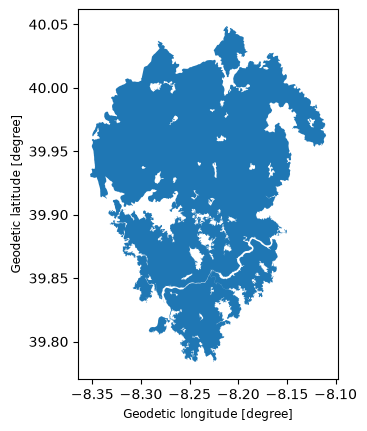

In [58]:
fp_1372 = fp_clip.loc[[1372]]
fp_1372.plot()

fp_1372.to_file(
    "../Data/fire_perimeter_1372.gpkg",
    driver="GPKG"
)

Here we have selected just one fire boundary - the largest in our area of interest.

In [41]:
fp_20170617 = fp_clip[fp_clip["DH_Inicio"] == "2017-06-17"]
fp_20170617

,Cod_SGIF,Cod_ANEPC,Ano,DH_Inicio,DH_1Interv,DH_Fim,Duracao_m,PI_DICOFRE,PI_NUTS3,PI_Distrit,...,Causa_Cod,Causa_Tipo,Causa_Desc,AreaHaSIG,AreaHaSGIF,AreaHaPov,AreaHaMato,AreaHaAgri,Edicao,geometry
832,BI2173830,2017050019786,2017,2017-06-17,2017-06-17,2017-06-17,62.0,050609,Beira Baixa,Castelo Branco,...,51,Natural,Naturais,201.818560,201.82,58.23,142.09,1.5,2018-07-19,"MULTIPOLYGON (((-7.74666 40.01627, -7.74666 40..."
833,BI2173833,2017050019798,2017,2017-06-17,2017-06-17,2017-06-20,3472.0,050609,Beira Baixa,Castelo Branco,...,51,Natural,Naturais,409.043449,409.41,111.59,293.12,4.7,2017-08-03,"MULTIPOLYGON (((-7.74883 40.00699, -7.74883 40..."
1113,BL217380,2017060026645,2017,2017-06-17,2017-06-17,2017-06-17,34.0,060905,Região de Coimbra,Coimbra,...,448,Intencional,Incendiarismo - Imputáveis,0.050488,0.05,0.00,0.05,0.0,2017-06-29,"POLYGON ((-8.30559 40.06607, -8.30537 40.06614..."
1372,BL4171577,2017100032538,2017,2017-06-17,2017-06-17,2017-06-22,6879.0,101302,Região de Leiria,Leiria,...,211,Negligente,Acidentais - Transportes e Comunicações,30617.851203,30358.84,30358.84,0.00,0.0,2018-01-31,"MULTIPOLYGON (((-8.35224 39.9316, -8.35224 39...."


<Axes: xlabel='Geodetic longitude [degree]', ylabel='Geodetic latitude [degree]'>

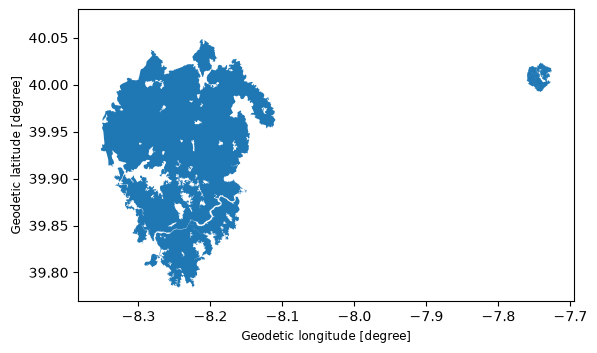

In [42]:
fp_20170617.plot()

Here we have selected all fire perimeters which started on the day that is reported as the day these most dangerous fires started and within our area of interest. 

,Cod_SGIF,Cod_ANEPC,Ano,DH_Inicio,DH_1Interv,DH_Fim,Duracao_m,PI_DICOFRE,PI_NUTS3,PI_Distrit,...,Causa_Cod,Causa_Tipo,Causa_Desc,AreaHaSIG,AreaHaSGIF,AreaHaPov,AreaHaMato,AreaHaAgri,Edicao,geometry
1376,BL4171971,2017100043917,2017,2017-08-11,2017-08-11,2017-08-14,4279.0,100209,Região de Leiria,Leiria,...,448,Intencional,Incendiarismo - Imputáveis,23759.687325,22824.488000,19610.570000,1550.188000,1663.7300,2018-01-31,"MULTIPOLYGON (((-8.34145 39.80153, -8.34145 39..."
876,BI2174095,2017050026123,2017,2017-08-23,2017-08-23,2017-08-24,1791.0,050914,Beira Baixa,Castelo Branco,...,449,Intencional,Incendiarismo - Imputáveis,269.622761,267.646000,190.866000,64.703000,12.0770,2018-07-19,"MULTIPOLYGON (((-7.99966 39.81853, -7.99915 39..."
884,BI2174147,2017050027511,2017,2017-09-08,2017-09-08,2017-09-11,3325.0,050911,Beira Baixa,Castelo Branco,...,211,Negligente,Acidentais - Transportes e Comunicações,4246.609994,3878.228000,2772.735000,823.642000,281.8510,2018-07-19,"MULTIPOLYGON (((-8.12268 39.86889, -8.12257 39..."
892,BI2174222,2017050030000,2017,2017-10-07,2017-10-07,2017-10-07,323.0,050917,Beira Baixa,Castelo Branco,...,449,Intencional,Incendiarismo - Imputáveis,5.672950,5.673000,5.673000,0.000000,0.0000,2018-07-19,"MULTIPOLYGON (((-7.97974 39.82671, -7.97964 39..."
831,BI2173826,2017050019660,2017,2017-06-16,2017-06-16,2017-06-16,134.0,050917,Beira Baixa,Castelo Branco,...,449,Intencional,Incendiarismo - Imputáveis,1.434199,1.560000,1.560000,0.000000,0.0000,2018-07-19,"POLYGON ((-8.01839 39.8361, -8.01839 39.8361, ..."
851,BI2173957,2017050023195,2017,2017-07-23,2017-07-23,2017-07-28,6376.0,050914,Beira Baixa,Castelo Branco,...,449,Intencional,Incendiarismo - Imputáveis,33711.753794,33639.680000,16579.060000,13178.860000,3881.7600,2018-07-19,"POLYGON ((-8.03155 39.81486, -8.03143 39.81552..."
820,BI2173102,2017050014004,2017,2017-04-24,2017-04-24,2017-04-24,93.0,050802,Beira Baixa,Castelo Branco,...,413,Negligente,Acidentais - Outros,0.686538,0.687000,0.687000,0.000000,0.0000,2018-07-19,"POLYGON ((-7.77937 39.79127, -7.77937 39.79127..."
821,BI2173176,2017050014296,2017,2017-04-27,2017-04-27,2017-04-27,286.0,050613,Beira Baixa,Castelo Branco,...,215,Negligente,Acidentais - Transportes e Comunicações,41.936377,41.930000,21.740000,19.030000,1.1600,2018-07-19,"MULTIPOLYGON (((-7.75268 39.92637, -7.75267 39..."
846,BI2173938,2017050022573,2017,2017-07-16,2017-07-16,2017-07-17,262.0,050613,Beira Baixa,Castelo Branco,...,449,Intencional,Incendiarismo - Imputáveis,5.552246,5.500000,5.500000,0.000000,0.0000,2018-07-19,"POLYGON ((-7.82478 39.94301, -7.82478 39.94301..."
893,BI2174224,2017050030039,2017,2017-10-07,2017-10-07,2017-10-08,1112.0,050613,Beira Baixa,Castelo Branco,...,227,Negligente,Acidentais - Maquinaria,54.732871,54.730000,49.100000,5.630000,0.0000,2018-07-19,"MULTIPOLYGON (((-7.77851 39.94782, -7.7785 39...."


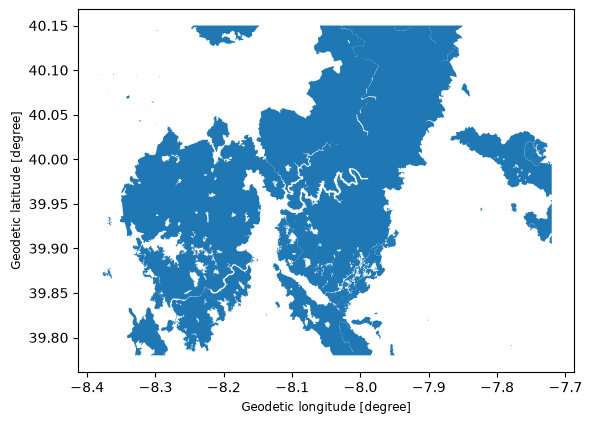

In [45]:
fp_clip_2 = gpd.clip(fp, bbox)
fp_clip_2.plot()
fp_clip_2

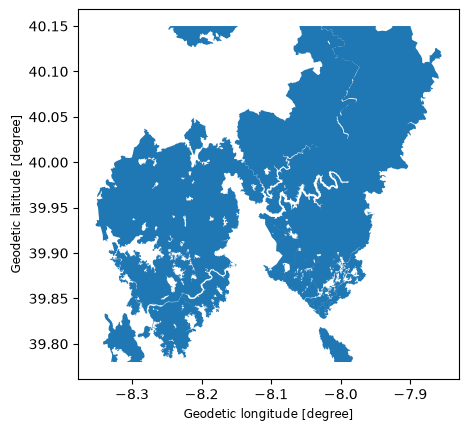

In [60]:
threshold = 10000 # Hectares

# Select only those perimeters with area over threshold 
fp_clip_2_large = fp_clip_2[fp_clip_2["AreaHaSIG"] > threshold] 
fp_clip_2_large.plot()

fp_clip_2_large.to_file(
    "../Data/fire_perimeter_large.gpkg",
    driver="GPKG"
)

### Choosing Boundaries

Must decide which boundaries to use. Select one specific fire or monitor all areas within boundary? 

<Axes: xlabel='Geodetic longitude [degree]', ylabel='Geodetic latitude [degree]'>

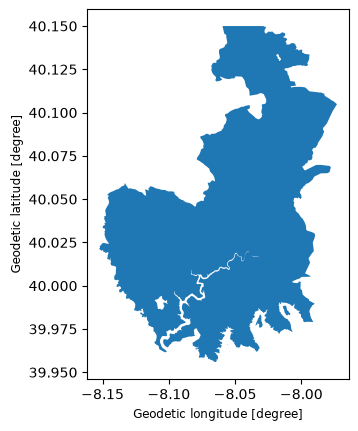

In [68]:
fp_clip_2_large.loc[[1112]].plot()

In [ ]:
1372 , 1112

In [64]:
fp_clip_2_large

,Cod_SGIF,Cod_ANEPC,Ano,DH_Inicio,DH_1Interv,DH_Fim,Duracao_m,PI_DICOFRE,PI_NUTS3,PI_Distrit,...,Causa_Cod,Causa_Tipo,Causa_Desc,AreaHaSIG,AreaHaSGIF,AreaHaPov,AreaHaMato,AreaHaAgri,Edicao,geometry
1376,BL4171971,2017100043917,2017,2017-08-11,2017-08-11,2017-08-14,4279.0,100209,Região de Leiria,Leiria,...,448,Intencional,Incendiarismo - Imputáveis,23759.687325,22824.488000,19610.570000,1550.188000,1663.7300,2018-01-31,"MULTIPOLYGON (((-8.34145 39.80153, -8.34145 39..."
851,BI2173957,2017050023195,2017,2017-07-23,2017-07-23,2017-07-28,6376.0,050914,Beira Baixa,Castelo Branco,...,449,Intencional,Incendiarismo - Imputáveis,33711.753794,33639.680000,16579.060000,13178.860000,3881.7600,2018-07-19,"POLYGON ((-8.03155 39.81486, -8.03143 39.81552..."
895,BI2174250,2017050030693,2017,2017-10-15,2017-10-15,2017-10-17,2406.0,050917,Beira Baixa,Castelo Branco,...,449,Intencional,Incendiarismo - Imputáveis,35421.531611,33192.611000,19279.198400,12703.934600,1209.4780,2018-07-19,"MULTIPOLYGON (((-8.11805 39.94074, -8.11786 39..."
1112,BL217377,2017060026571,2017,2017-06-17,2017-06-17,2017-06-22,7478.0,060601,Região de Coimbra,Coimbra,...,51,Natural,Naturais,17431.641987,17520.650000,9483.800000,8036.850000,0.0000,2018-01-31,"MULTIPOLYGON (((-8.15252 40.02157, -8.15252 40..."
1095,BL2171045,2017060046260,2017,2017-10-15,2017-10-15,2017-10-17,2510.0,060708,Região de Coimbra,Coimbra,...,211,Negligente,Acidentais - Transportes e Comunicações,67910.987594,53618.811555,47215.433221,909.954134,5493.4242,2018-07-05,"POLYGON ((-8.14786 40.14986, -8.14773 40.14972..."
1372,BL4171577,2017100032538,2017,2017-06-17,2017-06-17,2017-06-22,6879.0,101302,Região de Leiria,Leiria,...,211,Negligente,Acidentais - Transportes e Comunicações,30617.851203,30358.840000,30358.840000,0.000000,0.0000,2018-01-31,"MULTIPOLYGON (((-8.35224 39.9316, -8.35224 39...."


In [69]:
fp_selected = fp.loc[[1372, 1112]]

<Axes: xlabel='Geodetic longitude [degree]', ylabel='Geodetic latitude [degree]'>

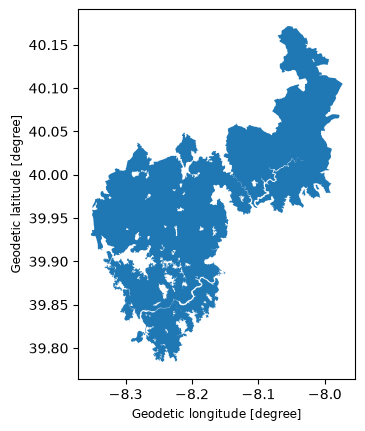

In [70]:
fp_selected.plot()

In [71]:
fp_selected.to_file(
    "../Data/selected_perimeters.gpkg",
    driver="GPKG"
)